# Workshop #4 — Gold Layer Integration, Data Quality Dimensions & Contract Validation
**Course:** Data Analysis Programming (*Programación para Análisis de Datos*) — Semester 2026-II  
**Team 1:** Natural Hazard Monitoring Systems — Earthquake Activity Monitoring  
**Authors:** Juan Córdoba (`20211020097`), Angelo Ibáñez (`20212020007`), Mauricio Sánchez (`20212020045`)

---

## Objective
This notebook validates end-to-end structural and mathematical fidelity between the **Silver Layer** (`datalake_silver/*.parquet`) and the **Gold Layer** (`datalake_gold/{governance,storytelling}_*.parquet`) that exclusively feeds the two Workshop #4 Dash applications (`:8050` and `:8051`). It integrates the course's **7 Data Quality Dimensions**, **MCAR/MAR/MNAR** missingness classification, and **Skewness / Outlier Treatment** frameworks directly over our multi-agency seismic telemetry.


## 1. Gold Contract Validation & Dataset Profiling


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from dashboard.gold_loader import load_gold
from scripts.validate_gold_contract import validate_gold_pair

GOLD_DIR = REPO_ROOT / "datalake_gold"
SILVER_DIR = REPO_ROOT / "datalake_silver"

ok, errors = validate_gold_pair(GOLD_DIR)
assert ok and not errors, f"Contract validation failed: {errors}"

gov_bundle = load_gold("governance", gold_dir=GOLD_DIR, force_reload=True)
story_bundle = load_gold("storytelling", gold_dir=GOLD_DIR, force_reload=True)
gov_df = gov_bundle.df
story_df = story_bundle.df

print(f"[PASS] Formal Gold Contract Validation: 0 errors")
print(f"Governance Gold : {gov_bundle.filename} -> {gov_df.shape[0]} rows x {gov_df.shape[1]} cols (computed_at={gov_bundle.computed_at})")
print(f"Storytelling Gold: {story_bundle.filename} -> {story_df.shape[0]} rows x {story_df.shape[1]} cols (computed_at={story_bundle.computed_at})")

# Course-style schema & null profile summary (df.info() equivalent)
profile_rows = []
for ds_name, frame in [("governance", gov_df), ("storytelling", story_df)]:
    for col in frame.columns:
        n_null = int(frame[col].isna().sum())
        profile_rows.append({
            "Dataset": ds_name,
            "Column": col,
            "Dtype": str(frame[col].dtype),
            "Non-Null": len(frame) - n_null,
            "Null %": round(100.0 * n_null / len(frame), 2),
        })
profile_df = pd.DataFrame(profile_rows)
display(profile_df.groupby("Dataset").agg(Columns=("Column", "count"), Avg_Null_Pct=("Null %", "mean")))


[PASS] Formal Gold Contract Validation: 0 errors
Governance Gold : governance_20261124_145929.parquet -> 123 rows x 13 cols (computed_at=2026-11-24T14:59:29Z)
Storytelling Gold: storytelling_20261124_145929.parquet -> 262 rows x 25 cols (computed_at=2026-11-24T14:59:29Z)


,Columns,Avg_Null_Pct
Dataset,,
governance,13,0.0000
storytelling,25,23.3892


## 2. Cross-Layer Silver ↔ Gold Volume & Energy Conservation


In [2]:
silver_files = sorted(SILVER_DIR.glob("*.parquet"))
silver_frames = [pd.read_parquet(p) for p in silver_files]
silver_raw = pd.concat(silver_frames, ignore_index=True)

# Deterministic deduplication matching src/gold_pyspark.py ordering
silver_sorted = silver_raw.sort_values(
    by=["event_id", "raw_time", "source_file"],
    ascending=[True, False, False],
    kind="mergesort",
)
silver_dedup = silver_sorted.drop_duplicates(subset=["event_id"], keep="first").copy()

def infer_source(row):
    eid = str(row["event_id"])
    sf = str(row["source_file"])
    if eid.startswith("emsc_fdsn_"):
        return "emsc_fdsn"
    if eid.startswith("gdacs_realtime_"):
        return "gdacs_realtime"
    if eid.startswith("usgs_realtime_") or "incremental" in sf or "usgs_rt_" in sf:
        return "usgs_realtime"
    return "usgs_fdsn"

silver_dedup["source_id"] = silver_dedup.apply(infer_source, axis=1)

gov_summary = gov_df[gov_df["kpi_category"] == "summary"].set_index("metric_name")["metric_value"]
sev_df = story_df[story_df["aggregation_type"] == "severity_distribution"]
dep_df = story_df[story_df["aggregation_type"] == "depth_regime_breakdown"]
vol_src_df = gov_df[gov_df["kpi_category"] == "volume_by_source"]

recon_checks = pd.DataFrame([
    {"Invariant": "Silver Parquet files read", "Silver_Direct": len(silver_files), "Gold_Reported": int(gov_df.loc[gov_df["metric_name"] == "total_silver_records_read", "secondary_value"].iloc[0])},
    {"Invariant": "Raw Silver records read", "Silver_Direct": len(silver_raw), "Gold_Reported": int(gov_summary["total_silver_records_read"])},
    {"Invariant": "Unique canonical events", "Silver_Direct": len(silver_dedup), "Gold_Reported": int(gov_summary["unique_deduplicated_events"])},
    {"Invariant": "Sum(Governance volume_by_source)", "Silver_Direct": len(silver_dedup), "Gold_Reported": int(vol_src_df["metric_value"].sum())},
    {"Invariant": "Sum(Storytelling severity_distribution)", "Silver_Direct": len(silver_dedup), "Gold_Reported": int(sev_df["event_count"].sum())},
    {"Invariant": "Sum(Storytelling depth_regime_breakdown)", "Silver_Direct": len(silver_dedup), "Gold_Reported": int(dep_df["event_count"].sum())},
])
recon_checks["Exact_Match"] = recon_checks["Silver_Direct"] == recon_checks["Gold_Reported"]
assert recon_checks["Exact_Match"].all(), "Cross-layer volume conservation failed!"
assert abs(float(sev_df["energy_share_pct"].sum()) - 100.0) <= 0.05, "Energy share conservation failed!"
display(recon_checks)
print(f"Radiated Energy Conservation: sum(energy_share_pct) = {sev_df['energy_share_pct'].sum():.4f}%")


,Invariant,Silver_Direct,Gold_Reported,Exact_Match
0,Silver Parquet files read,14,14,True
1,Raw Silver records read,9668,9668,True
2,Unique canonical events,4076,4076,True
3,Sum(Governance volume_by_source),4076,4076,True
4,Sum(Storytelling severity_distribution),4076,4076,True
5,Sum(Storytelling depth_regime_breakdown),4076,4076,True


Radiated Energy Conservation: sum(energy_share_pct) = 100.0000%


## 3. Systematic 7 Data Quality Dimensions Audit & Missingness Mechanisms (`MCAR` / `MAR` / `MNAR`)
Adapting the structured audit framework from our course's *Data Curation* module, we evaluate the curated telemetry across all **7 Data Quality Dimensions** (*Accuracy, Completeness, Consistency, Timeliness, Uniqueness, Validity, Integrity*) and classify structural missingness/imputation patterns.


In [3]:
pinned_cnt = int((silver_dedup["depth_km"].sub(10.0).abs() < 1e-4).sum())
pinned_pct = 100.0 * pinned_cnt / len(silver_dedup)
dup_rows = len(silver_raw) - len(silver_dedup)
dup_pct = 100.0 * dup_rows / len(silver_raw)
sig_df = story_df[story_df["aggregation_type"] == "recent_significant_events"]
non_usgs_tsunami_nulls = int(sig_df[~sig_df["source_id"].str.startswith("usgs_")]["tsunami_flag"].isna().sum())

dq_audit = pd.DataFrame([
    {
        "Dimension": "Completeness",
        "Target": "12 Silver canonical columns",
        "Finding": f"0 explicit nulls across {len(silver_dedup):,d} deduplicated events (0.00%)",
        "Mechanism / Policy": "Enforced at Silver boundary -> PASS",
    },
    {
        "Dimension": "Accuracy",
        "Target": "depth_km == 10.0 km",
        "Finding": f"{pinned_cnt:,d} events ({pinned_pct:.2f}%) fixed at agency default 10 km",
        "Mechanism / Policy": "MNAR (sparse vertical station geometry for shallow distant events) -> Flagged WARN (>25%)",
    },
    {
        "Dimension": "Completeness / Consistency",
        "Target": "tsunami_flag (EMSC & GDACS)",
        "Finding": f"{non_usgs_tsunami_nulls} non-USGS significant events carry tsunami_flag=None",
        "Mechanism / Policy": "MAR / Source-conditioned omission -> Preserved as None (never coerced to False)",
    },
    {
        "Dimension": "Uniqueness",
        "Target": "event_id across 14 Silver snapshots",
        "Finding": f"{dup_rows:,d} overlapping rows ({dup_pct:.2f}%) consolidated across polling snapshots",
        "Mechanism / Policy": "Deterministic latest-(raw_time, source_file) window deduplication",
    },
    {
        "Dimension": "Validity",
        "Target": "Coordinates, magnitude & focal depth",
        "Finding": "100.00% within [-90,90] lat, [-180,180] lon, [-2,10] M, [-5,800] km depth",
        "Mechanism / Policy": "Out-of-range records isolated into PostgreSQL rejected_record quarantine",
    },
    {
        "Dimension": "Integrity",
        "Target": "Multi-agency physical event overlap",
        "Finding": f"{int(gov_summary['cross_source_matched_pairs'])} cross-agency pairs in {int(gov_summary['event_groups_total'])} unified groups",
        "Mechanism / Policy": "1-to-1 greedy Haversine <=100 km & |dt|<=900 s reconciliation",
    },
    {
        "Dimension": "Timeliness",
        "Target": "Temporal anchor (max raw_time)",
        "Finding": f"Latest UTC event: {sig_df['event_timestamp_utc'].max()} | Gold computed: {gov_bundle.computed_at}",
        "Mechanism / Policy": "Cohorts (24h, 7d, 14d) anchored to max(raw_time) for deterministic reproducibility",
    },
])
display(dq_audit)


,Dimension,Target,Finding,Mechanism / Policy
0,Completeness,12 Silver canonical columns,"0 explicit nulls across 4,076 deduplicated eve...",Enforced at Silver boundary -> PASS
1,Accuracy,depth_km == 10.0 km,"1,403 events (34.42%) fixed at agency default ...",MNAR (sparse vertical station geometry for sha...
2,Completeness / Consistency,tsunami_flag (EMSC & GDACS),69 non-USGS significant events carry tsunami_f...,MAR / Source-conditioned omission -> Preserved...
3,Uniqueness,event_id across 14 Silver snapshots,"5,592 overlapping rows (57.84%) consolidated a...","Deterministic latest-(raw_time, source_file) w..."
4,Validity,"Coordinates, magnitude & focal depth","100.00% within [-90,90] lat, [-180,180] lon, [...",Out-of-range records isolated into PostgreSQL ...
5,Integrity,Multi-agency physical event overlap,730 cross-agency pairs in 680 unified groups,1-to-1 greedy Haversine <=100 km & |dt|<=900 s...
6,Timeliness,Temporal anchor (max raw_time),Latest UTC event: 2026-11-24T01:56:25Z | Gold ...,"Cohorts (24h, 7d, 14d) anchored to max(raw_tim..."


## 4. Distribution Shape, Skewness (Mean vs. Median) & Outlier Treatment Strategy


,Column,Mean,Q1,Median (Q2),Q3,IQR Outlier %,Skewness,Excess Kurtosis,Shape,Curation Action
0,magnitude,3.019969e+00,1.700000e+00,2.735000e+00,4.600000e+00,0.00,-0.007,-1.32,near-symmetric,Retain physical scale
1,depth_km,3.003239e+01,6.930000e+00,1.000000e+01,1.713250e+01,18.47,5.682,37.45,right-skewed,Keep physical deep subduction (>300 km)
2,energy_joules,2.518259e+12,2.238721e+07,7.990331e+08,5.011872e+11,14.97,22.996,629.74,right-skewed,Log10 transform -> log10_energy
3,log10_energy,9.329954e+00,7.350000e+00,8.902500e+00,1.170000e+01,0.00,-0.007,-1.32,near-symmetric,Retain physical scale


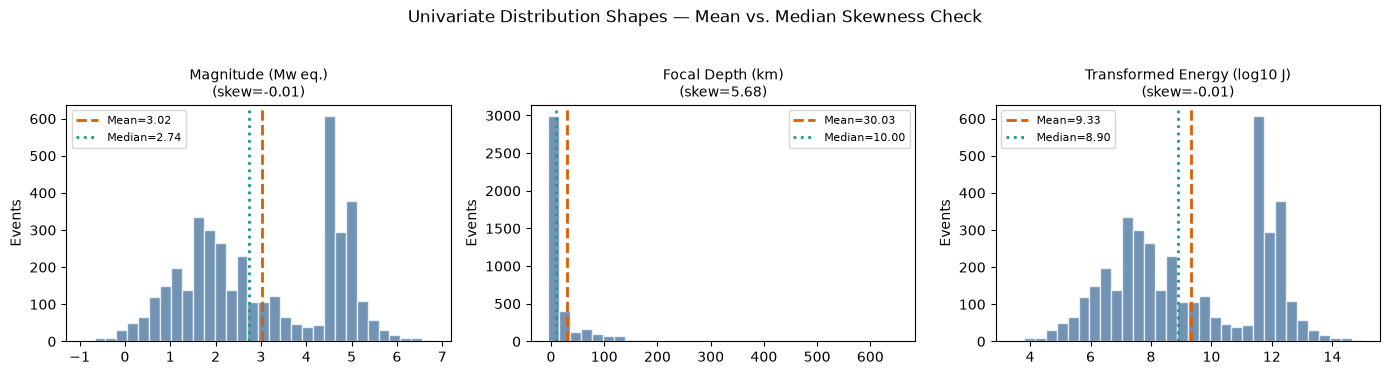

In [4]:
silver_dedup["log10_energy"] = 4.8 + 1.5 * silver_dedup["magnitude"]
numeric_cols = ["magnitude", "depth_km", "energy_joules", "log10_energy"]

shape_rows = []
for col in numeric_cols:
    s = silver_dedup[col].dropna()
    q1, q2, q3 = s.quantile(0.25), s.quantile(0.50), s.quantile(0.75)
    iqr = q3 - q1
    outliers = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    skew_val = float(s.skew())
    kurt_val = float(s.kurt())
    shape_rows.append({
        "Column": col,
        "Mean": s.mean(),
        "Q1": q1,
        "Median (Q2)": q2,
        "Q3": q3,
        "IQR Outlier %": round(100.0 * outliers / len(s), 2),
        "Skewness": round(skew_val, 3),
        "Excess Kurtosis": round(kurt_val, 2),
        "Shape": "right-skewed" if skew_val > 0.5 else ("left-skewed" if skew_val < -0.5 else "near-symmetric"),
        "Curation Action": (
            "Log10 transform -> log10_energy" if col == "energy_joules"
            else ("Keep physical deep subduction (>300 km)" if col == "depth_km" else "Retain physical scale")
        ),
    })

shape_df = pd.DataFrame(shape_rows)
display(shape_df)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, title in zip(
    axes,
    ["magnitude", "depth_km", "log10_energy"],
    ["Magnitude (Mw eq.)", "Focal Depth (km)", "Transformed Energy (log10 J)"],
):
    s = silver_dedup[col].dropna()
    ax.hist(s, bins=32, color="#3b6998", alpha=0.72, edgecolor="white")
    ax.axvline(s.mean(), color="#d95f02", lw=2, linestyle="--", label=f"Mean={s.mean():.2f}")
    ax.axvline(s.median(), color="#1b9e77", lw=2, linestyle=":", label=f"Median={s.median():.2f}")
    ax.set_title(f"{title}\n(skew={s.skew():.2f})", fontsize=10)
    ax.set_ylabel("Events")
    ax.legend(fontsize=8)
plt.suptitle("Univariate Distribution Shapes — Mean vs. Median Skewness Check", fontsize=12, y=1.03)
plt.tight_layout()
plt.show()


## 5. Independent Cross-Source Matching & Quarantine Verification


In [5]:
from datetime import datetime, timezone
from src.models import CanonicalEvent
from src.gold_pyspark import compute_dynamic_matching_metrics

canonical_events = [
    CanonicalEvent(
        event_id=str(r.event_id),
        source_id=str(r.source_id),
        timestamp=datetime.fromtimestamp(float(r.raw_time) / 1000.0, tz=timezone.utc),
        latitude=float(r.latitude),
        longitude=float(r.longitude),
        severity=float(r.magnitude),
        severity_unit=str(r.mag_type),
    )
    for r in silver_dedup[["event_id", "source_id", "raw_time", "latitude", "longitude", "magnitude", "mag_type"]].itertuples(index=False)
]

match_stats = compute_dynamic_matching_metrics(canonical_events)
print("Independent Dynamic Cross-Agency Matching Audit:", match_stats)
assert match_stats["cross_source_matched_pairs"] == int(gov_summary["cross_source_matched_pairs"])
assert match_stats["event_groups_total"] == int(gov_summary["event_groups_total"])

q_row = gov_df[gov_df["metric_name"] == "quarantined_records_detected"].iloc[0]
q_src = gov_df[gov_df["metric_name"] == "quarantine_source_status"].iloc[0]
print(f"Quarantine KPI -> value={q_row['metric_value']}, compliance_status={q_row['compliance_status']}, db_online_flag={q_src['metric_value']}")


2026-11-24 10:34:01 [INFO] src.gold_pyspark: Dynamic cross-source matching finished in 3.845s: pairs=730, groups=680 (2-agency=655, 3+-agency=25)


Independent Dynamic Cross-Agency Matching Audit: {'cross_source_matched_pairs': 730, 'event_groups_total': 680, 'total_grouped_events': 1385, 'group_size_2_count': 655, 'group_size_3plus_count': 25, 'group_size_distribution': {2: 655, 3: 25}, 'median_time_diff_sec': 0.435, 'median_dist_km': 5.255, 'mean_mag_diff': 0.038, 'elapsed_sec': 3.845}
Quarantine KPI -> value=3.0, compliance_status=PASS, db_online_flag=1.0


## 6. Daily SAAI Formula & Policy Threshold Verification (`SAAI = 0.4·z_N + 0.6·z_log10E`)


In [6]:
silver_dedup["period_date"] = pd.to_datetime(silver_dedup["raw_time"], unit="ms", utc=True).dt.strftime("%Y-%m-%d")
daily = silver_dedup.groupby("period_date", as_index=False).agg(
    event_count=("event_id", "count"),
    daily_energy=("energy_joules", "sum"),
    max_magnitude=("magnitude", "max"),
)
daily["log10_energy"] = np.log10(daily["daily_energy"].clip(lower=1.0))

for col, zcol in [("event_count", "z_n"), ("log10_energy", "z_e")]:
    std = daily[col].std(ddof=0)
    daily[zcol] = (daily[col] - daily[col].mean()) / std if std > 0 else 0.0

daily["saai_recomputed"] = (0.4 * daily["z_n"] + 0.6 * daily["z_e"]).round(3)

gold_ts = story_df[story_df["aggregation_type"] == "temporal_trend_saai"][
    ["period_date", "event_count", "max_magnitude", "saai_score", "alert_tier"]
].sort_values("period_date")

merged_saai = gold_ts.merge(daily[["period_date", "saai_recomputed"]], on="period_date")
max_diff = (merged_saai["saai_score"] - merged_saai["saai_recomputed"]).abs().max()
print(f"Max |Gold SAAI - Recomputed SAAI| across {len(merged_saai)} days: {max_diff:.6f}")
assert max_diff <= 1e-3, f"SAAI drift too large: {max_diff}"

print("\nAnomalous Seismic Days (SAAI >= 1.0):")
display(merged_saai[merged_saai["saai_score"] >= 1.0])


Max |Gold SAAI - Recomputed SAAI| across 46 days: 0.000000

Anomalous Seismic Days (SAAI >= 1.0):


,period_date,event_count,max_magnitude,saai_score,alert_tier,saai_recomputed
40,2026-11-16,228,6.6,1.535,ELEVATED,1.535
43,2026-11-21,61,6.8,1.076,ELEVATED,1.076


## 7. Component-to-Gold Traceability Matrix (`:8050` & `:8051`)


In [7]:
traceability = [
    ("Governance :8050", "7 Executive KPI Cards", "governance", "summary", len(gov_df[gov_df["kpi_category"] == "summary"])),
    ("Governance :8050", "Explicit Null & 10 km Pinning Chart", "governance", "null_rate_per_field", len(gov_df[gov_df["kpi_category"] == "null_rate_per_field"])),
    ("Governance :8050", "Daily / Cumulative Volume Chart", "governance", "volume_over_time", len(gov_df[gov_df["kpi_category"] == "volume_over_time"])),
    ("Governance :8050", "Tukey IQR Outlier Rate & Spread Charts", "governance", "outlier_rate_per_numeric_field", len(gov_df[gov_df["kpi_category"] == "outlier_rate_per_numeric_field"])),
    ("Governance :8050", "Location Descriptor Length Chart", "governance", "text_length_statistics", len(gov_df[gov_df["kpi_category"] == "text_length_statistics"])),
    ("Governance :8050", "Interactive SLA Audit DataTable", "governance", "ALL 6 categories", len(gov_df)),
    ("Storytelling :8051", "Panel A (Left) — Magnitude vs Energy Bar", "storytelling", "severity_distribution", len(story_df[story_df["aggregation_type"] == "severity_distribution"])),
    ("Storytelling :8051", "Panel A (Right) — 3-Class Depth Donut", "storytelling", "depth_regime_breakdown", len(story_df[story_df["aggregation_type"] == "depth_regime_breakdown"])),
    ("Storytelling :8051", "Panels B & C — Daily SAAI & Swarm Volume", "storytelling", "temporal_trend_saai", len(story_df[story_df["aggregation_type"] == "temporal_trend_saai"])),
    ("Storytelling :8051", "Panel D — Top 15 Tectonic Regions", "storytelling", "top_regions_keywords", len(story_df[story_df["aggregation_type"] == "top_regions_keywords"])),
    ("Storytelling :8051", "Panel E (Mode 1) — By Monitoring Network", "storytelling", "source_comparison", len(story_df[story_df["aggregation_type"] == "source_comparison"])),
    ("Storytelling :8051", "Panel E (Mode 2) — Historical vs Current", "storytelling", "historical_vs_current", len(story_df[story_df["aggregation_type"] == "historical_vs_current"])),
    ("Storytelling :8051", "Panel F — Global Significant Epicenter Map", "storytelling", "recent_significant_events", len(story_df[story_df["aggregation_type"] == "recent_significant_events"])),
]
trace_df = pd.DataFrame(traceability, columns=["Application", "UI Component", "Gold Dataset", "Slice Key", "Rows"])
assert (trace_df["Rows"] > 0).all(), "Every UI component must map to >= 1 Gold row!"
display(trace_df)


,Application,UI Component,Gold Dataset,Slice Key,Rows
0,Governance :8050,7 Executive KPI Cards,governance,summary,11
1,Governance :8050,Explicit Null & 10 km Pinning Chart,governance,null_rate_per_field,13
2,Governance :8050,Daily / Cumulative Volume Chart,governance,volume_over_time,87
3,Governance :8050,Tukey IQR Outlier Rate & Spread Charts,governance,outlier_rate_per_numeric_field,4
4,Governance :8050,Location Descriptor Length Chart,governance,text_length_statistics,4
5,Governance :8050,Interactive SLA Audit DataTable,governance,ALL 6 categories,123
6,Storytelling :8051,Panel A (Left) — Magnitude vs Energy Bar,storytelling,severity_distribution,5
7,Storytelling :8051,Panel A (Right) — 3-Class Depth Donut,storytelling,depth_regime_breakdown,3
8,Storytelling :8051,Panels B & C — Daily SAAI & Swarm Volume,storytelling,temporal_trend_saai,46
9,Storytelling :8051,Panel D — Top 15 Tectonic Regions,storytelling,top_regions_keywords,15
